# Applied Machine Learning (CSAI2017P) — Lab Assignment 6
## Spam Email Detection

Experiments 8 · CO2, CO4 · **10 marks**

| | |
|---|---|
| Name |Mansha |
| SAP ID | 590021940 |
| Batch | 06 |
| Due | announced in the lab |
| Lab quiz | LQ6, after submission |

**Datasets:** C2 (SMS Spam Collection)

---

### Before you start
- Attempt **2 of 3** in Section A, **1 of 2** in Section B. Section C is compulsory.
- Fit every transformer inside a `Pipeline`. Never fit on the test set.
- Set `random_state` wherever the question asks for reproducibility.
- Every question wants a short written observation, not just a number.
- Restart the kernel and run top-to-bottom before you submit.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.1.3
pandas       2.2.3
sklearn      1.6.1


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [5]:
# TODO: load the dataset for this assignment
# from sklearn.datasets import ...
# df = pd.read_csv('data/...')
df = pd.read_csv(
    "/content/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Shape:", df.shape)
df.head()


Shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Text to vectors  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Load the corpus and report the number of messages and the spam rate.
b. Fit a `CountVectorizer` and report the vocabulary size.
c. Show the ten most frequent tokens and state in two lines why they are useless for classification.


In [6]:
# A1 — code

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Number of messages:", len(df))
print(f"Spam rate: {(y == 'spam').mean() * 100:.2f}%")

vectorizer_pipe = Pipeline([
    ("vectorizer", CountVectorizer())
])

X_train_counts = vectorizer_pipe.fit_transform(X_train)

vectorizer = vectorizer_pipe.named_steps["vectorizer"]

print("Vocabulary size:", len(vectorizer.vocabulary_))

token_counts = np.asarray(X_train_counts.sum(axis=0)).ravel()
tokens = vectorizer.get_feature_names_out()

top_indices = token_counts.argsort()[::-1][:10]

top_tokens = pd.DataFrame({
    "Token": tokens[top_indices],
    "Count": token_counts[top_indices]
})

print("\nTen most frequent tokens:")
display(top_tokens)

Number of messages: 5572
Spam rate: 13.41%
Vocabulary size: 7708

Ten most frequent tokens:


,Token,Count
0,to,1789
1,you,1783
2,the,1034
3,and,788
4,is,721
5,in,720
6,me,668
7,my,615
8,it,594
9,your,571


**Observation (A1):**

> The corpus contains 5572 messages with a spam rate of 13.41%, and CountVectorizer produced a vocabulary of 7708 tokens. The ten most frequent tokens, such as “to”, “you”, “the”, and “and”, are common words that occur frequently in normal language. Since they are likely to appear in both ham and spam messages, their high frequency alone is not very useful for distinguishing between the two classes.

## A2. Naive Bayes  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Fit `MultinomialNB` on the counts and report accuracy, precision, recall and F1 on the spam class.
b. Print the confusion matrix.
c. State in two lines which words the model finds most spam-indicative.


In [7]:
# A2 — code

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

nb_model = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB())
])

nb_model.fit(X_train, y_train)

y_pred = nb_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="spam")
recall = recall_score(y_test, y_pred, pos_label="spam")
f1 = f1_score(y_test, y_pred, pos_label="spam")

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 score:  {f1 * 100:.2f}%")

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

print("\nConfusion Matrix:")
print(cm)

Accuracy:  98.03%
Precision: 97.04%
Recall:    87.92%
F1 score:  92.25%

Confusion Matrix:
[[962   4]
 [ 18 131]]


In [8]:
vectorizer = nb_model.named_steps["vectorizer"]
classifier = nb_model.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()

spam_index = list(classifier.classes_).index("spam")
ham_index = list(classifier.classes_).index("ham")

spam_score = (
    classifier.feature_log_prob_[spam_index]
    - classifier.feature_log_prob_[ham_index]
)

top_indices = np.argsort(spam_score)[-10:][::-1]

spam_words = pd.DataFrame({
    "Word": feature_names[top_indices],
    "Spam score": spam_score[top_indices]
})

print("\nMost spam-indicative words:")
display(spam_words)


Most spam-indicative words:


,Word,Spam score
0,claim,5.470276
1,prize,5.325445
2,150p,5.075984
3,tone,4.951932
4,18,4.695212
5,www,4.682942
6,guaranteed,4.645201
7,500,4.592558
8,cs,4.536988
9,awarded,4.478147


**Observation (A2):**

>The Multinomial Naive Bayes model achieved 98.03% accuracy, 97.04% precision, 87.92% recall and an F1 score of 92.25% on the spam class. The confusion matrix shows 4 false positives and 18 false negatives. Words such as “claim”, “prize”, “150p”, “guaranteed” and “awarded” are the most spam-indicative, as they occur relatively more often in spam messages than in legitimate messages.

## A3. Counts versus TF-IDF  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Refit the same classifier on `TfidfVectorizer` features.
b. Report the same four metrics and compare with A2 in a small table.
c. Explain in two lines what the IDF term is doing.


In [9]:
# A3 — code


**Observation (A3):**

> *write 2–6 lines here*

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. The cost of a false positive  &nbsp;&nbsp;`[4 marks]`

*Dataset: C2.*

a. For your best model, report precision and recall on the spam class at thresholds 0.3, 0.5, 0.7 and 0.9.
b. Plot the precision-recall curve and mark the four points.
c. A real filter sends spam to a junk folder. Argue in 6–8 lines which error is worse and pick an operating threshold.


In [10]:
# B1 — code
from sklearn.metrics import precision_recall_curve

spam_index = list(
    nb_model.named_steps["classifier"].classes_
).index("spam")

spam_prob = nb_model.predict_proba(X_test)[:, spam_index]

thresholds_to_test = [0.3, 0.5, 0.7, 0.9]

results = []

for threshold in thresholds_to_test:

    pred_threshold = np.where(
        spam_prob >= threshold,
        "spam",
        "ham"
    )

    p = precision_score(
        y_test,
        pred_threshold,
        pos_label="spam",
        zero_division=0
    )

    r = recall_score(
        y_test,
        pred_threshold,
        pos_label="spam",
        zero_division=0
    )

    results.append([
        threshold,
        p,
        r
    ])

threshold_results = pd.DataFrame(
    results,
    columns=["Threshold", "Precision", "Recall"]
)

display(threshold_results)

,Threshold,Precision,Recall
0,0.3,0.950704,0.906040
1,0.5,0.970370,0.879195
2,0.7,0.977273,0.865772
3,0.9,0.984496,0.852349


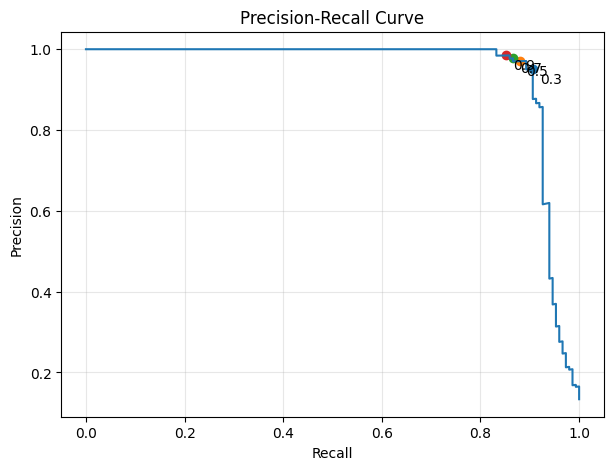

In [11]:
y_test_binary = (y_test == "spam").astype(int)

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test_binary,
    spam_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label="Precision-Recall curve"
)

for threshold, p, r in results:
    plt.scatter(r, p)
    plt.annotate(
        str(threshold),
        (r, p),
        xytext=(5, -10),
        textcoords="offset points"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(alpha=0.3)
plt.show()

**Observation (B1):**

> As the threshold increases from 0.3 to 0.9, precision rises from 95.07% to 98.45%, while recall falls from 90.60% to 85.23%. For a real spam filter, I consider a false positive more costly because a legitimate message sent to junk may be missed completely. A false negative is undesirable, but the spam remains visible and can still be deleted manually. I would choose a threshold of 0.7, which gives 97.73% precision while still maintaining 86.58% recall. Increasing it further to 0.9 provides only a small precision improvement while reducing recall further. Thus, 0.7 provides a suitable conservative trade-off for this filter.

## B2. n-grams and vocabulary size  &nbsp;&nbsp;`[4 marks]`

*Dataset: C2.*

a. Fit the same classifier with `ngram_range` of (1,1), (1,2) and (1,3).
b. Report vocabulary size, F1 and fit time for each in one table.
c. Explain in 4–6 lines what bigrams add, and at what point the extra features stop paying for themselves.


In [12]:
# B2 — code


**Observation (B2):**

> *write 2–6 lines here*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Break your own filter  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Write three spam messages by hand that your model classifies as ham.
b. In 4–6 lines, explain what property of bag-of-words you exploited and one defence against it.


In [13]:
# C1 — code

test_spam = [
    "Hey, hope you're doing well. I wanted to let you know that there is a reward waiting for you when you have some time to check it.",

    "Hi, just wanted to remind you about the special thing we discussed earlier. You can collect your gift whenever you're free.",

    "Hello, hope everything is going well. We selected you for a small reward, so please get in touch when you have a chance."
]

predictions = nb_model.predict(test_spam)

probabilities = nb_model.predict_proba(test_spam)[:, spam_index]

results_c1 = pd.DataFrame({
    "Message": test_spam,
    "Prediction": predictions,
    "Spam probability": probabilities
})

display(results_c1)

,Message,Prediction,Spam probability
0,"Hey, hope you're doing well. I wanted to let y...",ham,2.205569e-13
1,"Hi, just wanted to remind you about the specia...",ham,1.422290e-05
2,"Hello, hope everything is going well. We selec...",ham,3.611795e-07


**Observation (C1):**

> All three manually written spam messages were classified as ham, despite containing spam-like intentions such as rewards or gifts. I exploited the bag-of-words representation by using ordinary conversational wording and avoiding strongly spam-associated tokens. Bag-of-words mainly considers individual token occurrences and does not fully understand the meaning or context of a message. One defence is to use n-grams or contextual text representations that capture relationships between words and phrases rather than treating each word independently.

---

## Self-check before submitting

- [ ] Kernel restarted and run top-to-bottom, all outputs visible
- [ ] Every attempted question has a written observation
- [ ] No transformer fitted outside a pipeline
- [ ] Metrics reported with units where they have any
- [ ] File named `AML_LA06_<SAPID>.ipynb`
